# Data Science II | Pre-entrega 15
## Análisis de correlación del comportamiento del consumidor

**Pregunta de negocio:** entre los compradores de una tienda digital simulada, ¿más sesiones en el sitio durante los 30 días previos se asocian con pedidos de mayor importe?

**Producto analítico:** notebook reproducible con **Pearson, Spearman y Kendall**, evaluación de supuestos, visualizaciones, sensibilidad a outliers y recomendación de negocio.

**Origen y alcance:** datos **100 % sintéticos** creados para esta práctica; no son registros reales ni representativos de consumidores. Incluyen tres compras excepcionales introducidas deliberadamente para demostrar el efecto de observaciones influyentes. **Unidad de análisis:** una transacción por cliente. Los resultados son **descriptivos**, no una estimación causal ni una recomendación aplicable directamente a clientes reales.

| Etapa | Contenido |
|---|---|
| 01 | Adquisición, inspección y limpieza |
| 02 | Distribuciones, supuestos, outliers |
| 03 | Pearson, Spearman y Kendall |
| 04 | Robustez y sensibilidad |
| 05 | Interpretación, causalidad y decisión |

### 01 · Preparación de librerías y rutas
Se usa un CSV local versionado, de modo que el notebook funcione sin conexión. Las salidas se exportan a carpetas del repositorio.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().resolve()
if not (ROOT / 'datos' / 'transacciones_simuladas.csv').exists():
    ROOT = ROOT.parent
if not (ROOT / 'datos' / 'transacciones_simuladas.csv').exists():
    raise FileNotFoundError('Ejecutar desde la raíz o la carpeta notebooks del proyecto')
sys.path.insert(0, str(ROOT))

from src.analisis import X, Y, NUMERICAS, limpiar_datos, detectar_iqr, comparar_correlaciones, diagnostico

for directorio in ('graficos', 'resultados'):
    (ROOT / directorio).mkdir(exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.03)
COLOR_BASE = '#175F78'
COLOR_EXTREMO = '#B55432'
COLOR_SECUNDARIO = '#4C9A89'
pd.set_option('display.max_columns', 30)
print('Proyecto:', ROOT.name)
print('Python / entorno listo. Datos sin acceso a Internet.')

Proyecto: DSII_Preentrega_15_correlacion
Python / entorno listo. Datos sin acceso a Internet.


### 02 · Diccionario y procedencia

| Variable | Tipo | Significado |
|---|---|---|
| `id_transaccion` | Identificador | Pedido único |
| `cliente_id` | Identificador | Un cliente por pedido en este escenario |
| `fecha_compra` | Fecha | Momento de la operación |
| `sesiones_30d` | Numérica discreta | Sesiones digitales previas durante 30 días (**X**) |
| `importe_compra_usd` | Numérica continua | Importe del pedido en USD simulados (**Y**) |
| `antiguedad_cliente_dias` | Numérica discreta | Antigüedad en días del cliente |
| `productos_comprados` | Numérica discreta | Artículos simulados, derivados parcialmente del importe; **no usar como predictor independiente** |
| `canal` | Categórica | Web / App móvil |
| `medio_pago` | Categórica | Medio de pago simulado |

**Construcción:** `generar_datos.py` utiliza una semilla fija (`20261031`), 260 clientes y 2 copias duplicadas; se introdujeron 7 faltantes y 3 montos extraordinarios para controlar la calidad y demostrar sensibilidad. No hay datos personales reales. Se conserva el CSV generado para reproducir exactamente la entrega.

In [2]:
crudo = pd.read_csv(ROOT / 'datos' / 'transacciones_simuladas.csv', encoding='utf-8')
print('Filas de origen:', len(crudo))
print('Columnas:', list(crudo.columns))
print('Tipos detectados inicialmente:')
print(crudo.dtypes.to_string())
print('Nulos por campo:')
print(crudo.isna().sum().to_string())
display(crudo.head(5))

Filas de origen: 262
Columnas: ['id_transaccion', 'cliente_id', 'fecha_compra', 'sesiones_30d', 'importe_compra_usd', 'antiguedad_cliente_dias', 'productos_comprados', 'canal', 'medio_pago']
Tipos detectados inicialmente:
id_transaccion               int64
cliente_id                   int64
fecha_compra                object
sesiones_30d               float64
importe_compra_usd         float64
antiguedad_cliente_dias      int64
productos_comprados          int64
canal                       object
medio_pago                  object
Nulos por campo:
id_transaccion             0
cliente_id                 0
fecha_compra               0
sesiones_30d               3
importe_compra_usd         4
antiguedad_cliente_dias    0
productos_comprados        0
canal                      0
medio_pago                 0


,id_transaccion,cliente_id,fecha_compra,sesiones_30d,importe_compra_usd,antiguedad_cliente_dias,productos_comprados,canal,medio_pago
0,10001,20001,2026-04-15,13.0,202.26,509,3,App movil,Billetera digital
1,10002,20002,2026-05-02,7.0,113.85,1075,1,App movil,Tarjeta
2,10003,20003,2026-06-11,10.0,160.82,1389,2,App movil,Tarjeta
3,10004,20004,2026-02-11,8.0,131.63,910,2,Web,Billetera digital
4,10005,20005,2026-01-07,8.0,129.69,434,1,App movil,Tarjeta


### 03 · Limpieza y trazabilidad

Primero eliminamos duplicados por `id_transaccion`, convertimos tipos numéricos y fechas, y descartamos las filas sin **sesiones** o **importe**. No imputamos estas dos variables porque hacerlo para una correlación podría introducir asociaciones artificiales. Los registros con gastos extremos **se mantienen** para la estimación principal.

La decisión de exclusión aplica únicamente a observaciones incompletas; los outliers se revisan aparte.

In [3]:
datos, reporte_calidad = limpiar_datos(crudo)
print('Reporte de calidad:')
print(json.dumps(reporte_calidad, ensure_ascii=False, indent=2))
assert len(datos) == 253
assert datos[[X, Y]].notna().all().all()
assert datos['id_transaccion'].is_unique
print('Rango temporal:', datos['fecha_compra'].min().date(), 'a', datos['fecha_compra'].max().date())
print('Canales:', datos['canal'].value_counts().to_dict())
display(datos[[X, Y, 'canal']].describe(include='all').round(2))

Reporte de calidad:
{
  "filas_crudas": 262,
  "transacciones_duplicadas": 2,
  "nulos_criticos_despues_deduplicar": 7,
  "fechas_invalidas": 0,
  "filas_analizadas": 253,
  "regla": "una transacción por cliente; se descartan faltantes en las variables del par"
}
Rango temporal: 2026-01-01 a 2026-09-29
Canales: {'Web': 128, 'App movil': 125}


,sesiones_30d,importe_compra_usd,canal
count,253.00,253.00,253
unique,NaN,NaN,2
top,NaN,NaN,Web
freq,NaN,NaN,128
mean,9.26,148.96,NaN
std,4.48,170.45,NaN
min,2.00,12.06,NaN
25%,6.00,84.00,NaN
50%,8.00,121.61,NaN
75%,11.00,162.97,NaN


### 04 · Distribución y supuestos

Examinamos asimetría, curtosis (exceso) y la prueba de Shapiro-Wilk (H₀: normalidad). Si `p < 0.05`, hay evidencia incompatible con el supuesto de normalidad, aunque esto **no demuestra** una distribución alternativa concreta.

**Precisión conceptual:** Pearson puede calcularse aunque los datos no sean normales. Para interpretarlo y para algunos contrastes inferenciales importan adicionalmente la **linealidad**, los valores influyentes y el diseño de muestreo; no debe elegirse un coeficiente basándose solo en un test de normalidad.

In [4]:
resumen_distribucion = diagnostico(datos)
display(resumen_distribucion.round({'media': 2, 'mediana': 2, 'desviacion': 2,
                                    'asimetria': 2, 'curtosis_exceso': 2,
                                    'shapiro_w': 3, 'shapiro_p': 8}))
for fila in resumen_distribucion.itertuples():
    print(f'{fila.variable}: asimetría={fila.asimetria:.2f}, '
          f'curtosis(exceso)={fila.curtosis_exceso:.2f}, Shapiro p={fila.shapiro_p:.3e}')

,variable,n,media,mediana,desviacion,asimetria,curtosis_exceso,shapiro_w,shapiro_p
0,sesiones_30d,253,9.26,8.00,4.48,1.44,2.42,0.884,0.0
1,importe_compra_usd,253,148.96,121.61,170.45,8.23,82.61,0.375,0.0


sesiones_30d: asimetría=1.44, curtosis(exceso)=2.42, Shapiro p=5.297e-13
importe_compra_usd: asimetría=8.23, curtosis(exceso)=82.61, Shapiro p=1.260e-28


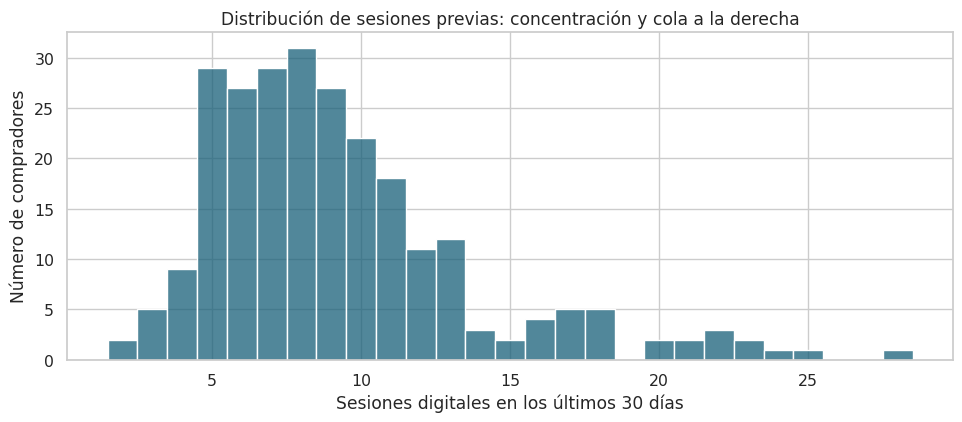

In [5]:
fig, ax = plt.subplots(figsize=(9.8, 4.4))
sns.histplot(datos[X], discrete=True, color=COLOR_BASE, ax=ax)
ax.set(title='Distribución de sesiones previas: concentración y cola a la derecha',
       xlabel='Sesiones digitales en los últimos 30 días', ylabel='Número de compradores')
fig.tight_layout()
fig.savefig(ROOT / 'graficos' / '01_histograma_sesiones.png', dpi=155)
plt.show()

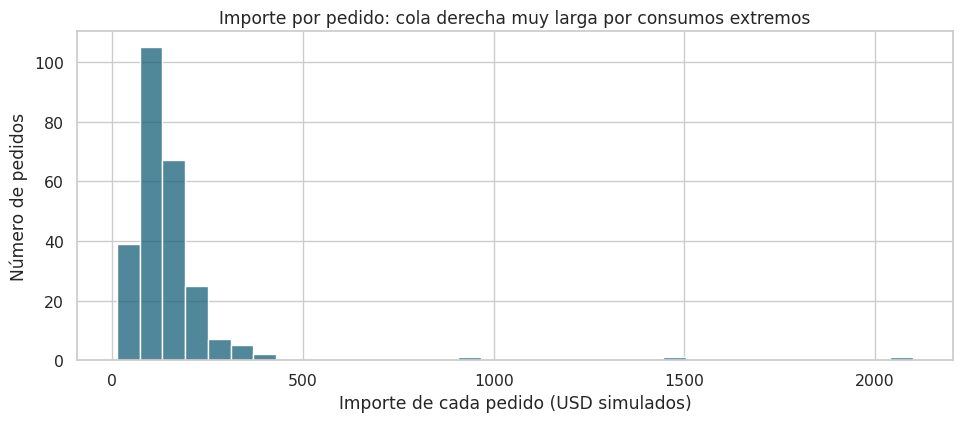

In [6]:
fig, ax = plt.subplots(figsize=(9.8, 4.4))
sns.histplot(datos[Y], bins=35, color=COLOR_BASE, ax=ax)
ax.set(title='Importe por pedido: cola derecha muy larga por consumos extremos',
       xlabel='Importe de cada pedido (USD simulados)', ylabel='Número de pedidos')
fig.tight_layout()
fig.savefig(ROOT / 'graficos' / '02_histograma_importes.png', dpi=155)
plt.show()

**Lectura:** en esta muestra artificial, las sesiones son discretas y presentan asimetría positiva. El importe tiene una cola derecha pronunciada, con compras excepcionales. Una media de gasto puede quedar dominada por pocos pedidos, por lo que conviene comparar también mediana y asociaciones por rangos. Los histogramas son descriptivos: por sí solos no establecen una relación entre X e Y.

### 05 · Identificación de outliers (IQR)

Se define `IQR = Q3 − Q1`, con límites `Q1 − 1.5 × IQR` y `Q3 + 1.5 × IQR`. Esta regla localiza **observaciones extremas**, pero **no prueba** que sean incorrectas. Los montos introducidos deliberadamente son `950`, `1450` y `2100` USD; otros importes altos pueden ser variación legítima de la simulación.

In [7]:
marcados, limites = detectar_iqr(datos, variable=Y)
print('Cuartiles y límites (USD simulados):')
print(json.dumps(limites, indent=2))
print('Registros señalados:')
display(marcados.loc[marcados['es_outlier_iqr'],
                     ['id_transaccion', X, Y, 'canal']].sort_values(Y, ascending=False))
marcados.loc[marcados['es_outlier_iqr'],
             ['id_transaccion', X, Y, 'canal']].to_csv(
                 ROOT / 'resultados' / 'registros_outliers_iqr.csv', index=False)

Cuartiles y límites (USD simulados):
{
  "q1": 84.0,
  "q3": 162.97,
  "iqr": 78.97,
  "limite_inferior": -34.455,
  "limite_superior": 281.425,
  "cantidad_marcados": 13
}
Registros señalados:


,id_transaccion,sesiones_30d,importe_compra_usd,canal
203,10209,2.0,2100.00,App movil
93,10096,5.0,1450.00,Web
7,10008,3.0,950.00,App movil
234,10241,28.0,426.66,App movil
56,10059,24.0,382.30,Web
61,10064,22.0,359.04,App movil
130,10133,25.0,345.03,Web
126,10129,23.0,344.44,Web
51,10054,20.0,327.10,App movil
243,10251,23.0,310.64,Web


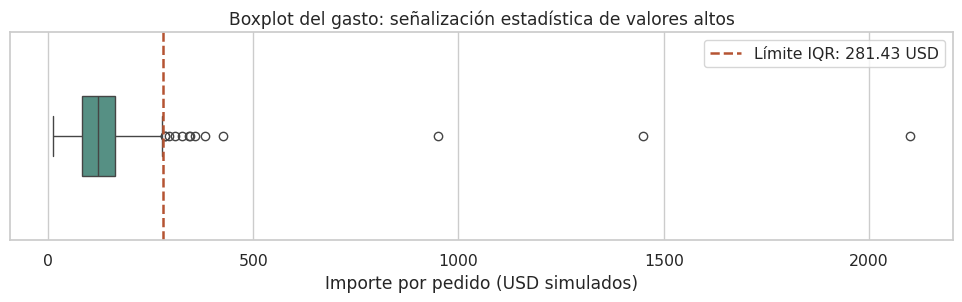

In [8]:
fig, ax = plt.subplots(figsize=(9.8, 3.2))
sns.boxplot(x=datos[Y], color=COLOR_SECUNDARIO, ax=ax, width=.38)
ax.axvline(limites['limite_superior'], color=COLOR_EXTREMO, linestyle='--', linewidth=1.8,
           label=f"Límite IQR: {limites['limite_superior']:.2f} USD")
ax.set(title='Boxplot del gasto: señalización estadística de valores altos',
       xlabel='Importe por pedido (USD simulados)')
ax.legend(loc='upper right', frameon=True)
fig.tight_layout()
fig.savefig(ROOT / 'graficos' / '03_boxplot_outliers.png', dpi=155)
plt.show()

### 06 · ¿Lineal o monótona? Relación visual entre sesiones y gasto

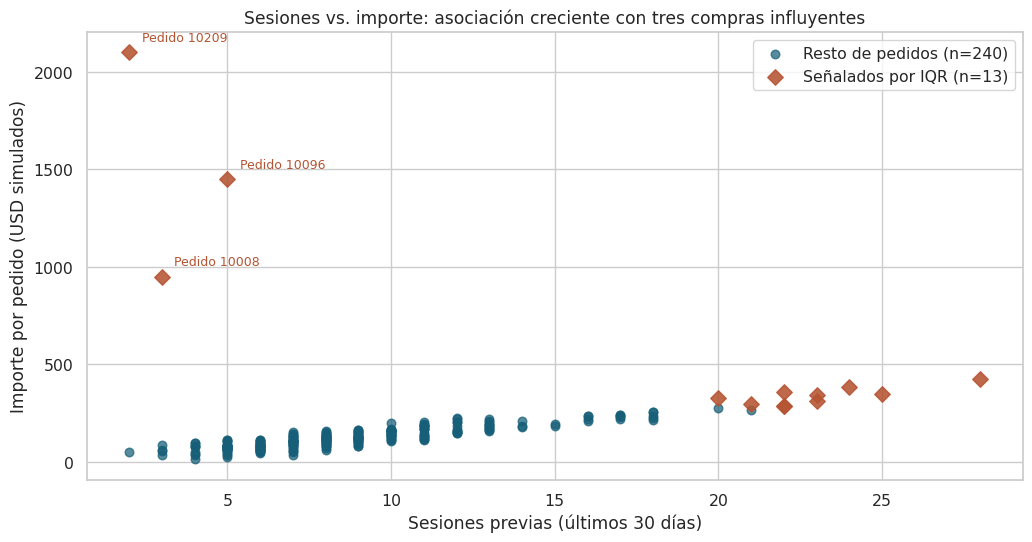

In [9]:
normales = marcados.loc[~marcados['es_outlier_iqr']]
extremos = marcados.loc[marcados['es_outlier_iqr']]
fig, ax = plt.subplots(figsize=(10.5, 5.6))
ax.scatter(normales[X], normales[Y], color=COLOR_BASE, s=38, alpha=.72,
           label=f'Resto de pedidos (n={len(normales)})')
ax.scatter(extremos[X], extremos[Y], color=COLOR_EXTREMO, s=62, alpha=.88,
           label=f'Señalados por IQR (n={len(extremos)})', marker='D')
for identificador in (10008, 10096, 10209):
    fila = marcados.loc[marcados.id_transaccion == identificador].iloc[0]
    ax.annotate(f'Pedido {identificador}', (fila[X], fila[Y]), xytext=(9, 8),
                textcoords='offset points', fontsize=9, color=COLOR_EXTREMO)
ax.set(title='Sesiones vs. importe: asociación creciente con tres compras influyentes',
       xlabel='Sesiones previas (últimos 30 días)', ylabel='Importe por pedido (USD simulados)')
ax.legend(loc='upper right', frameon=True)
fig.tight_layout()
fig.savefig(ROOT / 'graficos' / '04_dispersion_con_outliers.png', dpi=155)
plt.show()

**Interpretación:** al excluir **solamente para una prueba de sensibilidad** los puntos marcados por IQR, el patrón de crecimiento es mucho más compacto. Los tres montos excepcionalmente altos, asociados a pocas sesiones, perturban la covarianza lineal de Pearson. En cambio, Spearman conserva mejor la información de **orden** entre clientes.

No corresponde eliminar automáticamente los outliers del dataset final: podrían reflejar compras legítimas de alto valor. Un analista debe inspeccionar origen, reglas de negocio y posibles cambios de segmento.

### 07 · Tres coeficientes sobre exactamente las mismas observaciones

- **Pearson (r):** intensidad de asociación **lineal** entre variables numéricas; sensible a magnitud y puntos influyentes.
- **Spearman (ρ):** correlación de **rangos**; útil para tendencias **monótonas**, incluso si no son estrictamente lineales, con menor sensibilidad a la **magnitud** de outliers.
- **Kendall (τ-b):** concordancia de pares de observaciones; útil como contraste robusto y ajusta empates de rango.

**Importante:** los tres coeficientes pertenecen a escalas entre −1 y +1 pero **no representan magnitudes de asociación directamente intercambiables**. No se debe concluir que τ-b es peor que ρ por ser numéricamente menor.


PEARSON | matriz de correlación


,sesiones_30d,importe_compra_usd,antiguedad_cliente_dias
sesiones_30d,1.000,0.231,0.055
importe_compra_usd,0.231,1.000,0.033
antiguedad_cliente_dias,0.055,0.033,1.000


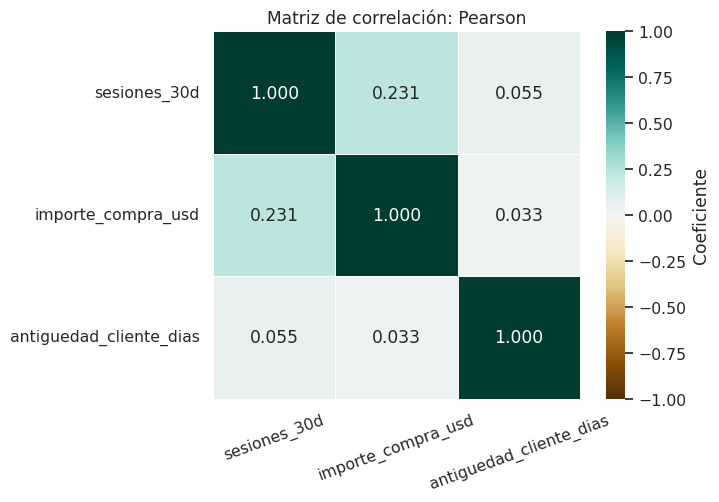


SPEARMAN | matriz de correlación


,sesiones_30d,importe_compra_usd,antiguedad_cliente_dias
sesiones_30d,1.000,0.828,0.059
importe_compra_usd,0.828,1.000,0.077
antiguedad_cliente_dias,0.059,0.077,1.000


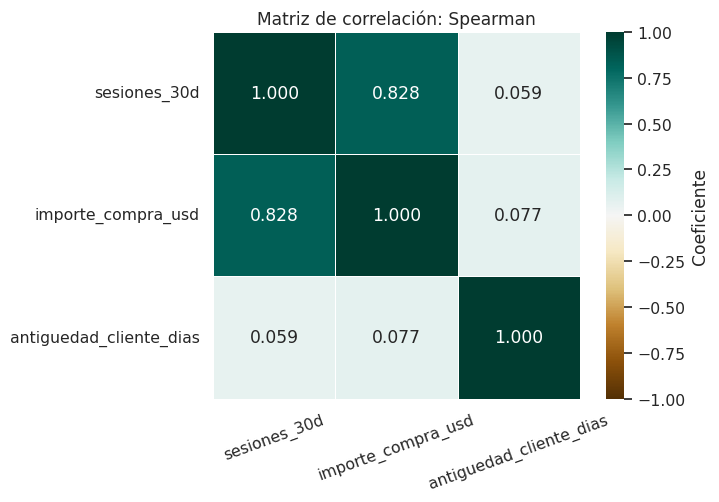


KENDALL | matriz de correlación


,sesiones_30d,importe_compra_usd,antiguedad_cliente_dias
sesiones_30d,1.000,0.698,0.041
importe_compra_usd,0.698,1.000,0.051
antiguedad_cliente_dias,0.041,0.051,1.000


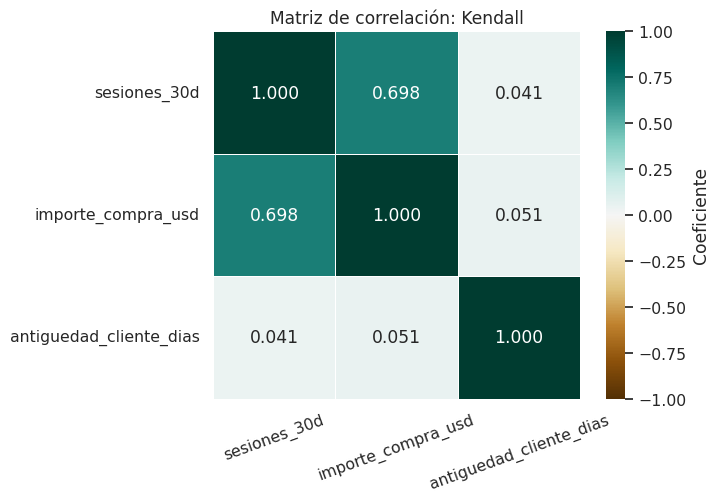

In [10]:
variables_matriz = [X, Y, 'antiguedad_cliente_dias']
matrices = {}
for metodo in ('pearson', 'spearman', 'kendall'):
    matrices[metodo] = datos[variables_matriz].corr(method=metodo)
    print(f'\n{metodo.upper()} | matriz de correlación')
    display(matrices[metodo].round(3))
    fig, ax = plt.subplots(figsize=(7.3, 5.2))
    sns.heatmap(matrices[metodo], annot=True, fmt='.3f', vmin=-1, vmax=1, center=0,
                cmap='BrBG', square=True, linewidths=.6, cbar_kws={'label':'Coeficiente'}, ax=ax)
    ax.set_title(f'Matriz de correlación: {metodo.capitalize()}')
    ax.tick_params(axis='x', rotation=20)
    ax.tick_params(axis='y', rotation=0)
    fig.tight_layout()
    fig.savefig(ROOT / 'graficos' / f'0{5 + list(matrices).index(metodo)}_matriz_{metodo}.png', dpi=155)
    plt.show()

Comparación de métodos y sensibilidad ante exclusión estadística:


,metodo,todos_los_registros,sin_marcados_iqr_solo_sensibilidad
0,Pearson,0.231,0.896
1,Spearman,0.828,0.876
2,Kendall,0.698,0.716


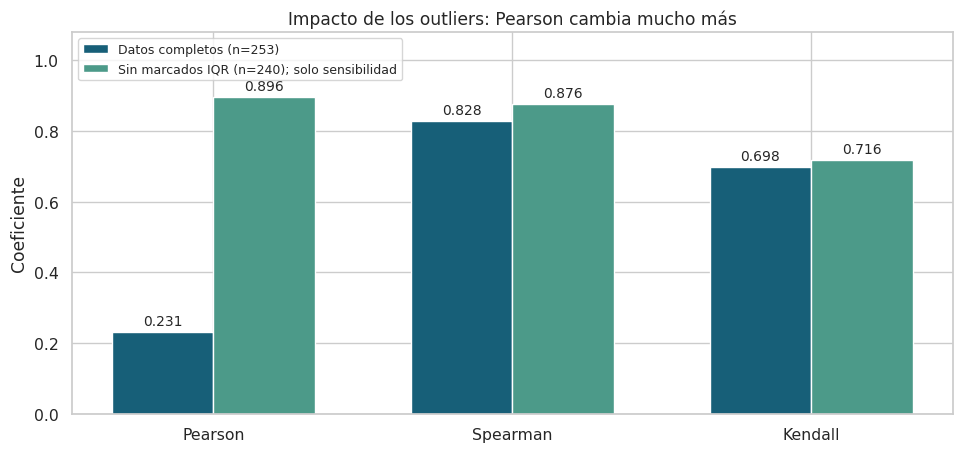

In [11]:
comparacion = comparar_correlaciones(datos)
print('Comparación de métodos y sensibilidad ante exclusión estadística:')
display(comparacion.round(3))
comparacion.to_csv(ROOT / 'resultados' / 'comparacion_coeficientes.csv', index=False)

fig, ax = plt.subplots(figsize=(9.8, 4.7))
pos = np.arange(len(comparacion))
ancho = .34
b1 = ax.bar(pos - ancho/2, comparacion['todos_los_registros'], ancho,
            color=COLOR_BASE, label='Datos completos (n=253)')
b2 = ax.bar(pos + ancho/2, comparacion['sin_marcados_iqr_solo_sensibilidad'], ancho,
            color=COLOR_SECUNDARIO, label='Sin marcados IQR (n=240); solo sensibilidad')
ax.bar_label(b1, fmt='%.3f', padding=3, fontsize=10)
ax.bar_label(b2, fmt='%.3f', padding=3, fontsize=10)
ax.set_xticks(pos, comparacion['metodo'])
ax.set_ylim(0, 1.08)
ax.set_ylabel('Coeficiente')
ax.set_title('Impacto de los outliers: Pearson cambia mucho más')
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout()
fig.savefig(ROOT / 'graficos' / '08_comparacion_sensibilidad.png', dpi=155)
plt.show()

### 08 · Interpretación de resultados y significado de negocio

| Indicador en dataset completo (n=253) | Valor | Lectura concreta |
|---|---:|---|
| Pearson | **0.231** | Asociación lineal positiva **débil** si se considera todo el dataset con extremos |
| Spearman | **0.828** | Asociación monótona positiva **fuerte**: las mayores sesiones suelen corresponder a mayores montos en el ordenamiento |
| Kendall tau-b | **0.698** | Concordancia positiva marcada entre el orden de las sesiones y el de los importes, considerando empates |
| Outliers de importe por IQR | **13** | Requieren inspección; no equivalen a errores ni justifican eliminación inmediata |
| Pearson sin marcados IQR | **0.896** | En el subconjunto de sensibilidad aparece una relación lineal mucho mayor |

**Elección metodológica:** para describir la asociación en el conjunto completo, **Spearman** es la métrica central porque el importe presenta asimetría extrema, la relación es mayormente monótona y los montos grandes tienen influencia desproporcionada sobre Pearson. **Kendall tau-b** funciona como contraste robusto de concordancia; Pearson sigue siendo útil para diagnosticar qué cambia si se evalúa únicamente una relación lineal.

**Cuidado estadístico:** interpretar ρ = 0.828 no significa que *cada nueva sesión aumente el gasto 82.8 %*; es una asociación entre **rangos**, no una tasa de crecimiento, una probabilidad, ni el efecto de una intervención.

**Decisión de negocio:** si fueran datos reales, se propondría analizar segmentos de frecuencia de sesiones, importe y canal, investigar los pedidos extremos y contrastar si la tendencia se repite fuera de esta muestra. La evidencia no alcanza para recomendar acciones comerciales automáticas.

In [12]:
# Exploración por canal para comprobar si el hallazgo persiste en subgrupos:
resumen_por_canal = pd.DataFrame([
    {'canal': nombre, 'pedidos': len(grupo),
     'spearman_sesiones_importe': grupo[X].corr(grupo[Y], method='spearman')}
    for nombre, grupo in datos.groupby('canal')
])
display(resumen_por_canal.round(3))
resumen_por_canal.to_csv(ROOT / 'resultados' / 'comparacion_por_canal.csv', index=False)

,canal,pedidos,spearman_sesiones_importe
0,App movil,125,0.810
1,Web,128,0.845


### 09 · Correlación no significa causalidad

Que dos variables evolucionen juntas **no demuestra** que una provoque la otra. En este caso podrían intervenir el presupuesto personal, promociones, campañas, categoría de producto, necesidades del comprador, estacionalidad y factores no medidos. Además, el conjunto contiene **solo clientes que compraron** (selección de población) y fue **simulado** con una regla que introduce asociación intencional: no es evidencia experimental.

Para examinar causalidad harían falta una pregunta causal definida, datos reales adecuados, control explícito de confusores o un experimento como A/B cuando sea viable y ético.

### 10 · Conclusión ejecutiva

**Hallazgo.** En este ejercicio simulado, existe una asociación monótona positiva fuerte entre sesiones digitales e importe de compra, pero tres operaciones extraordinarias con pocas sesiones reducen mucho la correlación lineal de Pearson.

**Recomendación.** Reportar **Spearman como indicador principal y Kendall como validación**, junto con la correlación de Pearson y un análisis de sensibilidad a los valores extremos. Auditar los outliers antes de decidir transformaciones o exclusiones y verificar el patrón con datos reales por segmento. **No atribuir a las sesiones un efecto causal sobre el gasto ni desplegar decisiones comerciales sobre este dataset artificial.**

**Limitaciones.** Población sintética; una transacción por comprador; sin validación externa; Shapiro sensible al tamaño muestral; correlaciones descriptivas y no causales. La comparación sin puntos IQR es un diagnóstico, no la versión definitiva de los datos.

In [13]:
resumen_final = {
    'origen': 'sintetico_20261031',
    'filas_analizadas': len(datos),
    'filas_crudas': len(crudo),
    'outliers_importe_iqr': limites['cantidad_marcados'],
    'metodo_elegido': 'Spearman',
    'coeficientes': {
        str(fila.metodo).lower(): {
            'completo': round(float(fila.todos_los_registros), 6),
            'sensibilidad_sin_iqr': round(float(fila.sin_marcados_iqr_solo_sensibilidad), 6)
        }
        for fila in comparacion.itertuples(index=False)
    },
    'advertencia': 'Correlacion no implica causalidad; dataset simulado'
}
(ROOT / 'resultados' / 'resumen_analisis.json').write_text(
    json.dumps(resumen_final, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print('VALIDACIÓN FINAL: OK')
print('Análisis con 253 observaciones; 3 coeficientes y 13 outliers identificados.')
print('Se exportaron figuras PNG y tablas CSV/JSON reproducibles.')

VALIDACIÓN FINAL: OK
Análisis con 253 observaciones; 3 coeficientes y 13 outliers identificados.
Se exportaron figuras PNG y tablas CSV/JSON reproducibles.
